In [1]:
%pip install matplotlib-label-lines


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [3]:
%pip install xgboost 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [5]:
import os, warnings
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

warnings.filterwarnings("ignore")  

In [6]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [7]:
DATASET_NAME = 'moratuwa_mc_2014-2018'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [8]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [10]:
df = pd.read_csv("../Datasets/moratuwa_mc_2014-2018.csv")

In [11]:
df.head(5)

,area,ticket_date,waste_type,net_weight_kg
0,Moratuwa MC,2014-01-12,Sorted Organic Waste,47230
1,Moratuwa MC,2014-02-12,Sorted Organic Waste,54670
2,Moratuwa MC,2014-03-12,Sorted Organic Waste,43670
3,Moratuwa MC,2014-04-12,Sorted Organic Waste,40410
4,Moratuwa MC,2014-05-12,Sorted Organic Waste,34590


In [12]:
df.shape

(6691, 4)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6691 entries, 0 to 6690
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   area           6691 non-null   object
 1   ticket_date    6691 non-null   object
 2   waste_type     6691 non-null   object
 3   net_weight_kg  6691 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 209.2+ KB


In [14]:
df.describe()

,net_weight_kg
count,6691.000000
mean,17914.148857
std,26863.105733
min,0.000000
25%,2320.000000
50%,5810.000000
75%,19755.000000
max,506430.000000


Check missing data

In [15]:
print(df['net_weight_kg'].isna().sum())

0


In [16]:
print(df['ticket_date'].duplicated().sum())


5315


In [17]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [18]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2014-01-12 00:00:00 to 2018-12-11 00:00:00


In [19]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [20]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [21]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 419
DatetimeIndex(['2014-01-13', '2014-01-14', '2014-01-15', '2014-01-16',
               '2014-01-17', '2014-01-18', '2014-01-19', '2014-01-20',
               '2014-01-21', '2014-01-22',
               ...
               '2018-07-01', '2018-07-12', '2018-07-25', '2018-08-01',
               '2018-08-12', '2018-09-01', '2018-09-12', '2018-10-12',
               '2018-11-12', '2018-12-01'],
              dtype='datetime64[ns]', length=419, freq=None)


In [22]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 9
Percentage of zero values: 0.13450904199671201 %


checking outliers

In [23]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: -23832.5
Upper limit: 45907.5
Number of potential outliers: 953
     ticket_date  net_weight_kg
0     2014-01-12          47230
1     2014-02-12          54670
6     2014-08-12          47700
7     2014-09-12          50190
21    2014-10-12          65970
...          ...            ...
6664  2018-12-06          84530
6669  2018-12-07          62100
6670  2018-12-08          85510
6684  2018-12-10          84800
6690  2018-12-11          83910

[953 rows x 2 columns]


In [24]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [25]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       80733.266332
Monday       83206.497462
Saturday     98489.343434
Sunday       94601.052632
Thursday     85236.040609
Tuesday      87518.636364
Wednesday    80257.309645
Name: net_weight_kg, dtype: float64


In [26]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     82028.558559
2     84553.000000
3     82919.745763
4     87792.782609
5     95761.844660
6     91462.783505
7     90674.489796
8     99889.649123
9     83798.983051
10    81054.328358
11    83416.928571
12    85932.711864
Name: net_weight_kg, dtype: float64


Find the categories under waste_type.

In [27]:
waste_type_list = list(df['waste_type'].unique())

Preprocess datasets.

In [28]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [29]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [30]:
df.columns

Index(['area', 'ticket_date', 'waste_type', 'net_weight_kg', 'year', 'month'], dtype='object')

###Filter the `ticket_date` and `net_weight_kg` columns.

In [31]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [32]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

### Extract 2015 to 2018

In [33]:
df = df.loc[~(df['ticket_date'].dt.year < 2015)]
df = df.reset_index(drop=True)

### Get dates between 2015-01-01 and 2018-12-31.

In [34]:
date_range_df = pd.date_range(start="2015-01-01", end="2018-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

### Add the complete date range to the df.

In [35]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

### Convert `net_waste_kg` to numeric.

In [36]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

### Available values

In [37]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 1308


### Missing values in net_weight_kg

In [38]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 153


In [39]:
df.isnull().sum()

ticket_date        0
net_weight_kg    153
dtype: int64

In [40]:
df = df.fillna(-100000)

In [41]:
df.isnull().sum()

ticket_date      0
net_weight_kg    0
dtype: int64

In [42]:
df = df.set_index('ticket_date')

In [43]:
%pip install adtk

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: adtk in c:\users\dell user\appdata\local\programs\python\python310\lib\site-packages (0.6.2)




[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [44]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2015-01-01 00:00:00+00:00,63550.0
2015-01-02 00:00:00+00:00,94850.0
2015-01-03 00:00:00+00:00,96180.0
2015-01-04 00:00:00+00:00,122270.0
2015-01-05 00:00:00+00:00,99420.0
...,...
2018-12-27 00:00:00+00:00,-100000.0
2018-12-28 00:00:00+00:00,-100000.0
2018-12-29 00:00:00+00:00,-100000.0


[<Axes: >]

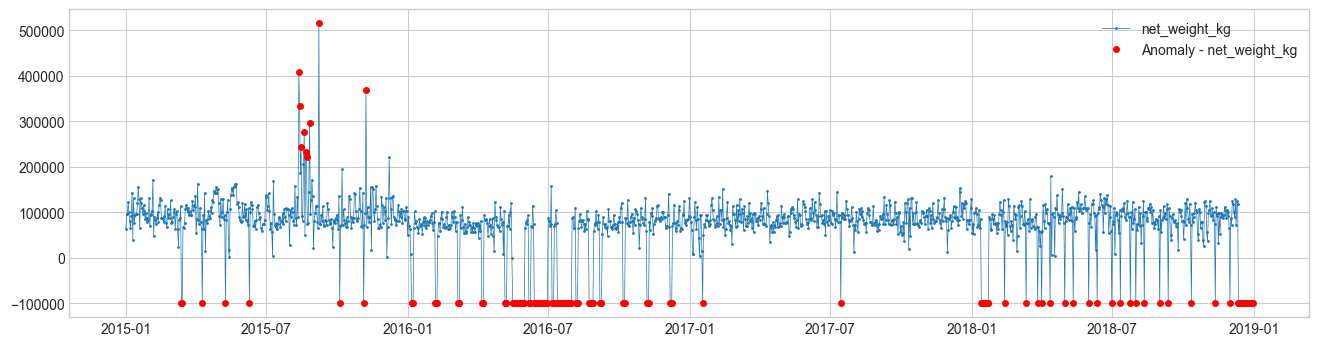

In [45]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

Remove outliers

In [46]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [47]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

#original - 29

outliers: 9


In [48]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [49]:
df = df.reset_index()

Set (Saturdays, Sundays) detected as outliers to 0

In [50]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

### Waste Data Visualization

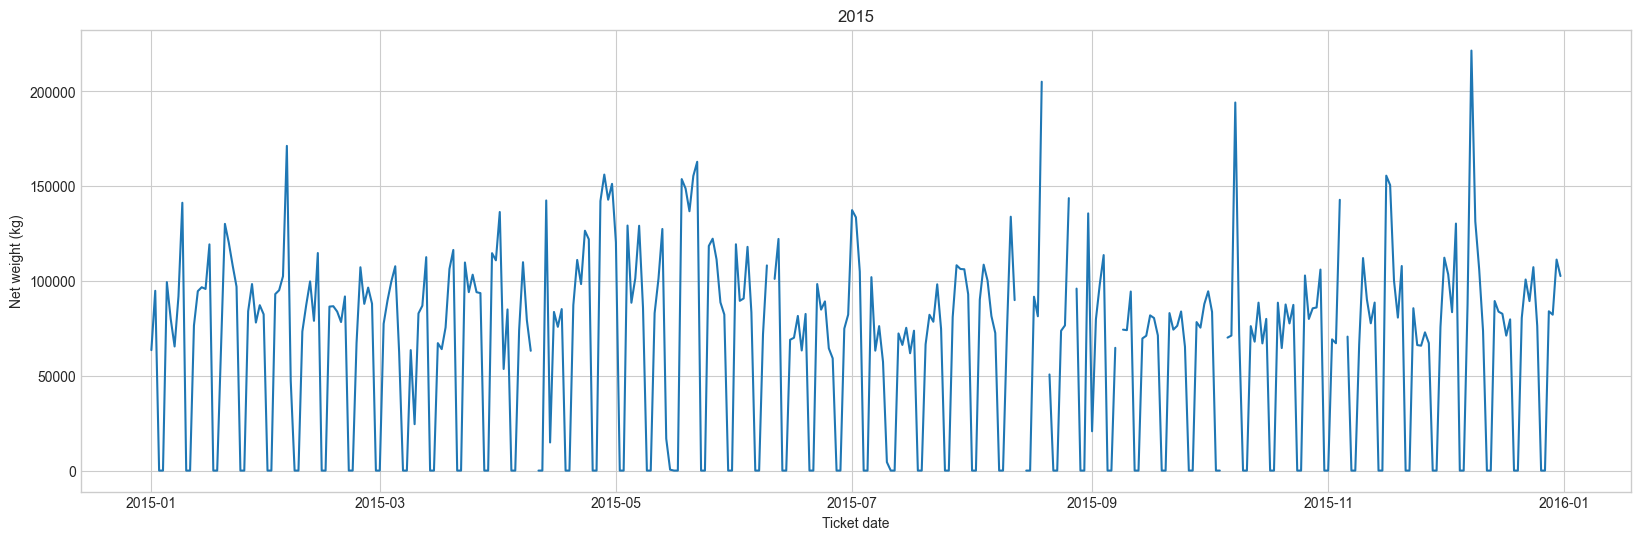

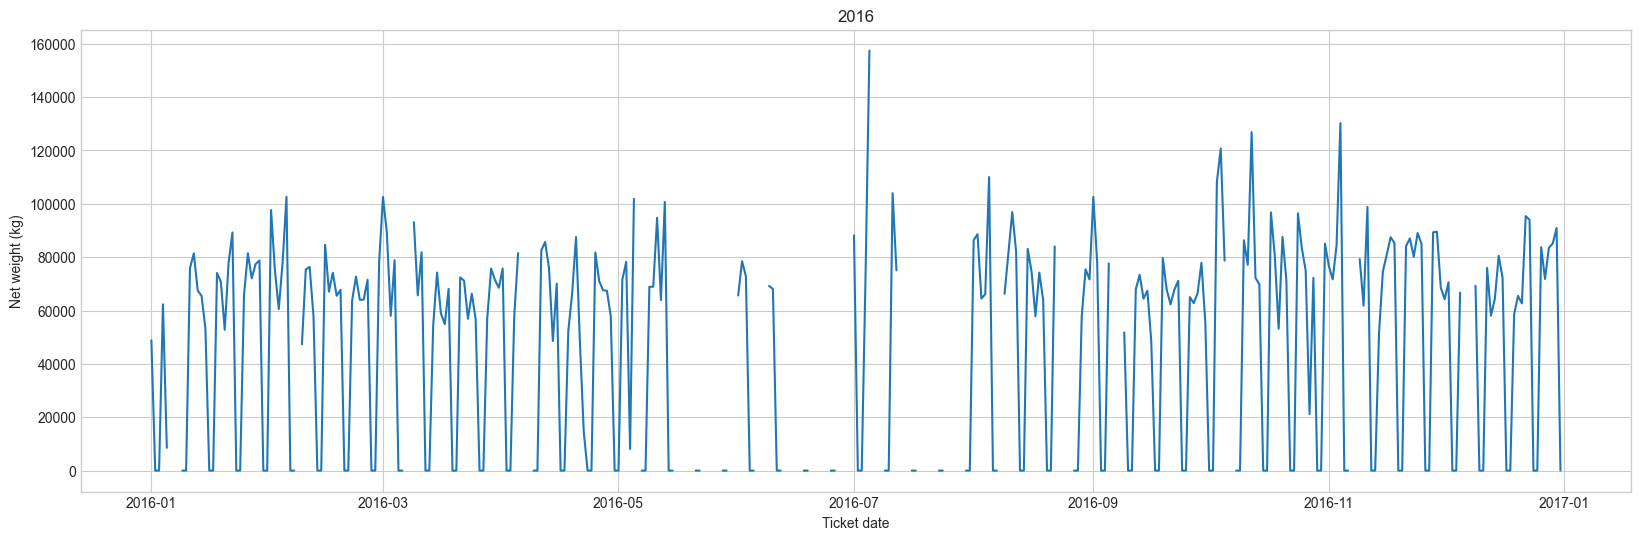

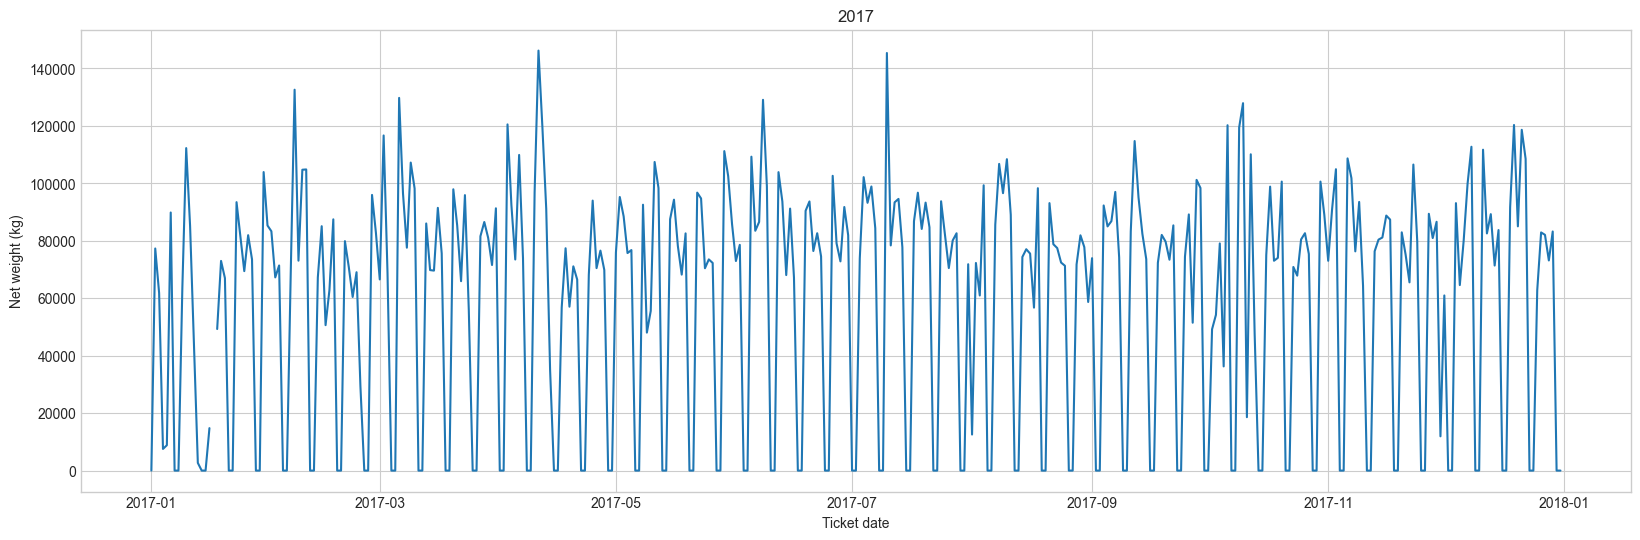

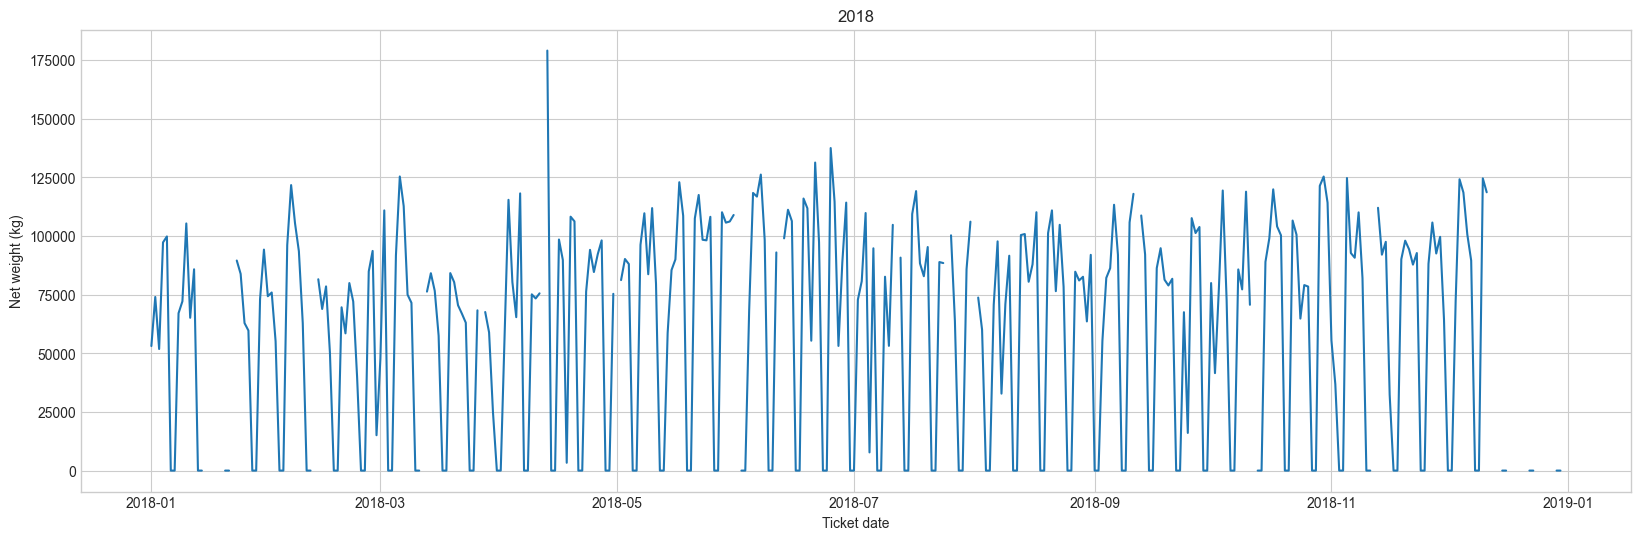

In [51]:
for year in range(2015, 2019):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [52]:
lag_count_list = [42, 360, 150, 120, 49, 14, 90]
estimator_count_list = [10, 100, 1000]
max_depth_list = [7, 3, 8 , 9, 4, 6]
subsample_list = [0.6, 0.9, 0.7, 0.8]
eta_list = [0.01, 0.3, 0.1]

n_iter = (len(lag_count_list) * len(estimator_count_list) * len(max_depth_list)
          * len(subsample_list) * len(eta_list))
print("Total configurations:", n_iter)

Total configurations: 1512


In [53]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    df_temp = df.copy()

    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = df_temp['net_weight_kg'].shift(i)

    lag_columns = [f'net_weight_kg_lag_{i}' for i in range(1, lag_count + 1)]
    df_temp = df_temp.dropna(subset=['net_weight_kg'] + lag_columns)

    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    split_index = int(len(df_temp) * 0.8)            # time order: first 80% train, last 20% test
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count, random_state=0, max_depth=max_depth,
        subsample=subsample, learning_rate=eta,
        objective='reg:squarederror', n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return sqrt(mean_squared_error(y_test, y_pred))

In [54]:
DATASET_NAME = "Moratuwa"
PREPROCESSING_CACHE_DIR_PATH = f'../preprocessing_cache_{DATASET_NAME}_full'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)
os.makedirs("../grid_search_results", exist_ok=True)

results, errors = [], []

with tqdm(total=n_iter, desc="Grid Search") as pbar:
    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:
                        filename = (f'lag-{lag_count}_est-{estimator_count}_dpt-{max_depth}'
                                    f'_subsmp-{subsample}_eta-{eta}.json')
                        file_path = os.path.join(PREPROCESSING_CACHE_DIR_PATH, filename)
                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(lag_count, estimator_count, max_depth, subsample, eta)
                                summary = {'rmse': float(rmse), 'lag_count': lag_count,
                                           'estimator_count': estimator_count, 'max_depth': max_depth,
                                           'subsample': subsample, 'eta': eta}
                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)
                            results.append(summary)
                        except Exception as e:
                            errors.append({'filename': filename, 'error': str(e)})
                        finally:
                            pbar.update(1)

print("Successful results:", len(results), "| Failed:", len(errors))
if errors: print(errors[:3])

results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
display(results_df)
results_df.to_csv("../grid_search_results/all_grid_search_results_Moratuwa.csv", index=False)    # CHANGED: local path

Grid Search:   0%|          | 0/1512 [00:00<?, ?it/s]

Successful results: 1512 | Failed: 0


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,0.000000,360,1000,7,0.9,0.01
1,0.000000,360,100,3,0.6,0.30
2,0.000000,360,100,3,0.6,0.01
3,0.000000,360,100,7,0.8,0.10
4,0.000000,360,100,7,0.8,0.30
...,...,...,...,...,...,...
1507,42438.110165,14,10,7,0.7,0.01
1508,42442.829892,14,10,8,0.7,0.01
1509,42449.299767,14,10,8,0.6,0.01
1510,42458.429880,14,10,9,0.7,0.01


In [55]:
# all results, best (lowest RMSE) first
results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
print("Top 10 settings")
display(results_df.head(10))

Top 10 settings


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,0.0,360,1000,7,0.9,0.01
1,0.0,360,100,3,0.6,0.30
2,0.0,360,100,3,0.6,0.01
3,0.0,360,100,7,0.8,0.10
4,0.0,360,100,7,0.8,0.30
5,0.0,360,100,7,0.8,0.01
6,0.0,360,100,7,0.7,0.10
7,0.0,360,100,7,0.7,0.30
8,0.0,360,100,7,0.7,0.01
9,0.0,360,100,7,0.9,0.10


In [56]:
# best setting for each lag count
best_per_lag = results_df.loc[results_df.groupby('lag_count')['rmse'].idxmin()].sort_values('rmse')
print("Best setting for each lag count")
display(best_per_lag)

def to_params(row):
    return {'rmse': float(row['rmse']), 'lag_count': int(row['lag_count']),
            'estimator_count': int(row['estimator_count']), 'max_depth': int(row['max_depth']),
            'subsample': float(row['subsample']), 'eta': float(row['eta'])}

Best setting for each lag count


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,0.000000,360,1000,7,0.9,0.01
216,15962.381934,150,1000,4,0.6,0.10
229,17173.286279,42,10,4,0.6,0.30
236,17247.874886,120,100,3,0.6,0.30
272,17715.896746,49,10,3,0.6,0.30
367,18510.378437,90,10,3,0.7,0.30
636,19837.617865,14,10,4,0.9,0.30


In [57]:
#  optimum-lag model = the lowest RMSE of all settings
optimum_lag_model_params = to_params(best_per_lag.iloc[0])

In [58]:

# minimum-lag model = the lowest RMSE among lag counts that fit before the first blank day
null_rows = df.index[df['net_weight_kg'].isna()]
first_null_index = int(null_rows[0]) if len(null_rows) > 0 else len(df)
print("First blank row index:", first_null_index)

short_ok = best_per_lag[best_per_lag['lag_count'] < first_null_index]
if len(short_ok) == 0:
    raise ValueError(f"No lag count below {first_null_index} was tested. "
                     "Add a smaller lag (for example 7 or 14) to lag_count_list and run the search again.")
minimum_lag_model_params = to_params(short_ok.iloc[0])

print("\nOptimum lag model:", optimum_lag_model_params)
print("Minimum lag model:", minimum_lag_model_params)

First blank row index: 99

Optimum lag model: {'rmse': 0.0, 'lag_count': 360, 'estimator_count': 1000, 'max_depth': 7, 'subsample': 0.9, 'eta': 0.01}
Minimum lag model: {'rmse': 17173.286278864798, 'lag_count': 42, 'estimator_count': 10, 'max_depth': 4, 'subsample': 0.6, 'eta': 0.3}


In [59]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    try:
        mape = mean_absolute_percentage_error(actual, predicted)
    except Exception:
        mape = None
    print('RMSE:', rmse, '| MAE:', mae, '| MAPE:', mape)

    plt.figure(figsize=(20, 6), dpi=100)
    plt.plot(np.asarray(actual))
    plt.plot(np.asarray(predicted))
    if plot_title:                                  
        plt.title(plot_title)
    plt.show()
    return rmse, mae, mape

RMSE: 0.0 | MAE: 0.0 | MAPE: 0.0


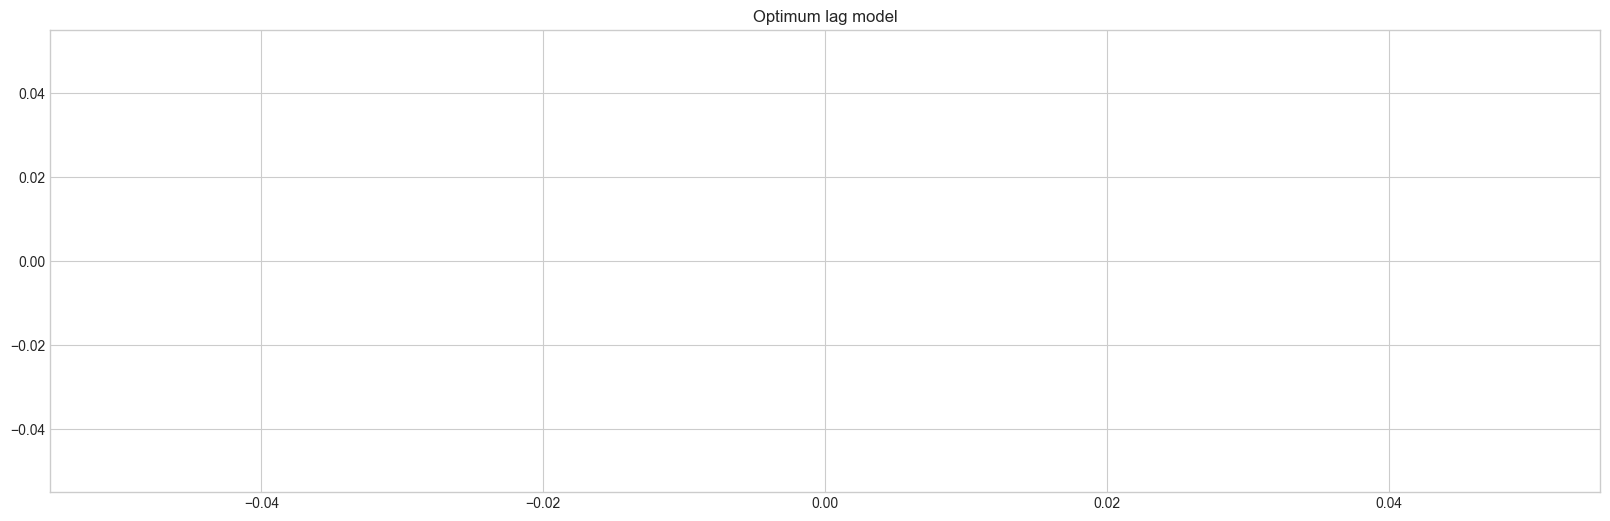

Baseline RMSE (same weekday last week): 0.0


In [60]:
df_temp = df.copy()                                         

for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta'])
model_optimum.fit(X_train, y_train)
y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Optimum lag model")

if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

RMSE: 17173.286231819464 | MAE: 11330.7197265625 | MAPE: 3.6471364193039155e+18


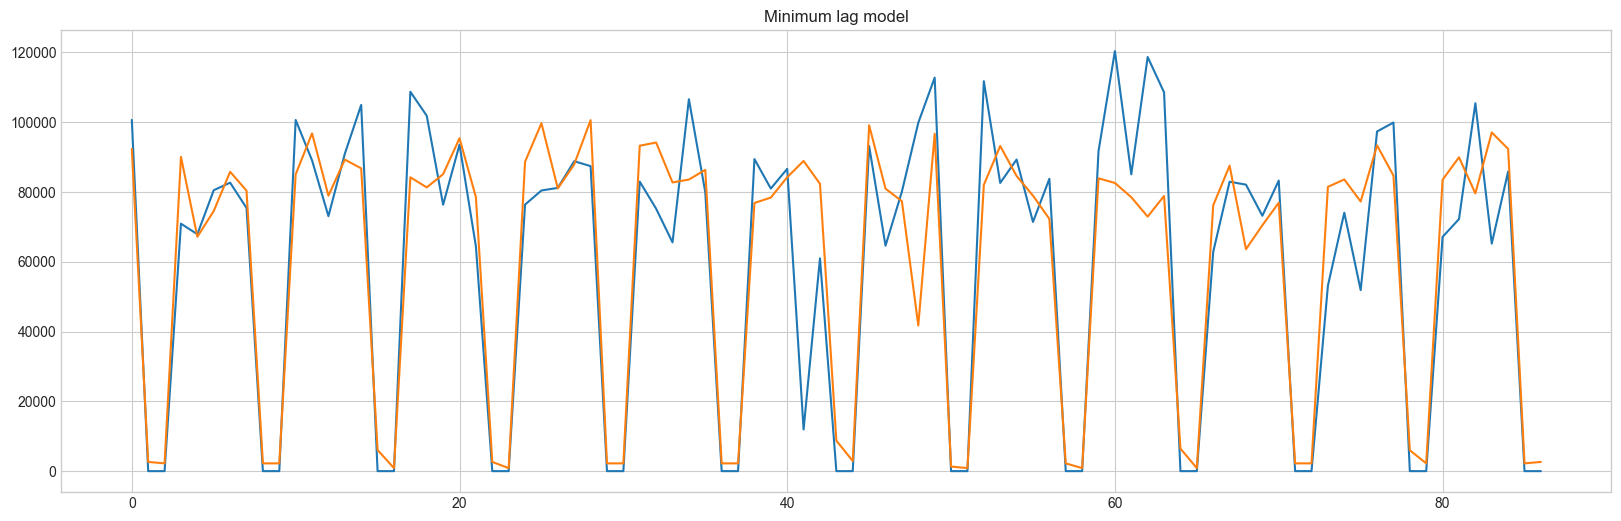

Baseline RMSE (same weekday last week): 24057.37817858767


In [61]:
df_temp = df.copy()                                          # complete series (as in the authors' pipeline)

for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
df_temp = df_temp.dropna()
del df_temp['ticket_date']

X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

cut = int(len(X) * 0.8)                                      # CHANGED: time order
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y[:cut], y[cut:]

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta'])
model_minimum.fit(X_train, y_train)
y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred, "Minimum lag model")

# baseline = same weekday last week (needs a lag count of at least 7)
if "net_weight_kg_lag_7" in X_test.columns:
    base = X_test["net_weight_kg_lag_7"].to_numpy()
    print("Baseline RMSE (same weekday last week):", sqrt(mean_squared_error(y_test, base)))
else:
    print("Baseline skipped: this model uses fewer than 7 lags.")

In [62]:
df['predicted_net_weight_kg'] = np.nan

for index in df.index:
    if pd.isnull(df.at[index, 'net_weight_kg']):

        if index > optimum_lag_model_params['lag_count']:
            lag = optimum_lag_model_params['lag_count']
            model = model_optimum
        else:
            lag = minimum_lag_model_params['lag_count']
            model = model_minimum

        previous_values = df['net_weight_kg'].iloc[index - lag:index].tolist()[::-1]
        column_list = ['net_weight_kg_lag_{}'.format(i) for i in range(1, lag + 1)]
        previous_df = pd.DataFrame([previous_values], columns=column_list)

        value = float(max(model.predict(previous_df)[0], 0.0))   # CHANGED: no negative weights
        df.at[index, 'net_weight_kg'] = value
        df.at[index, 'predicted_net_weight_kg'] = value

In [63]:
n_imputed = int(df["predicted_net_weight_kg"].count())
print(f"Imputed values: {n_imputed}")
print(f"Percentage of imputed values: {n_imputed / len(df) * 100:.2f} %")   # CHANGED
print(f"Mean of imputed values: {df['predicted_net_weight_kg'].mean()}")
print(f"SD of imputed values: {df['predicted_net_weight_kg'].std()}")
print("Blanks left:", df['net_weight_kg'].isna().sum())                      # should be 0

Imputed values: 113
Percentage of imputed values: 7.73 %
Mean of imputed values: 6777.473243915929
SD of imputed values: 23422.997226633906
Blanks left: 0


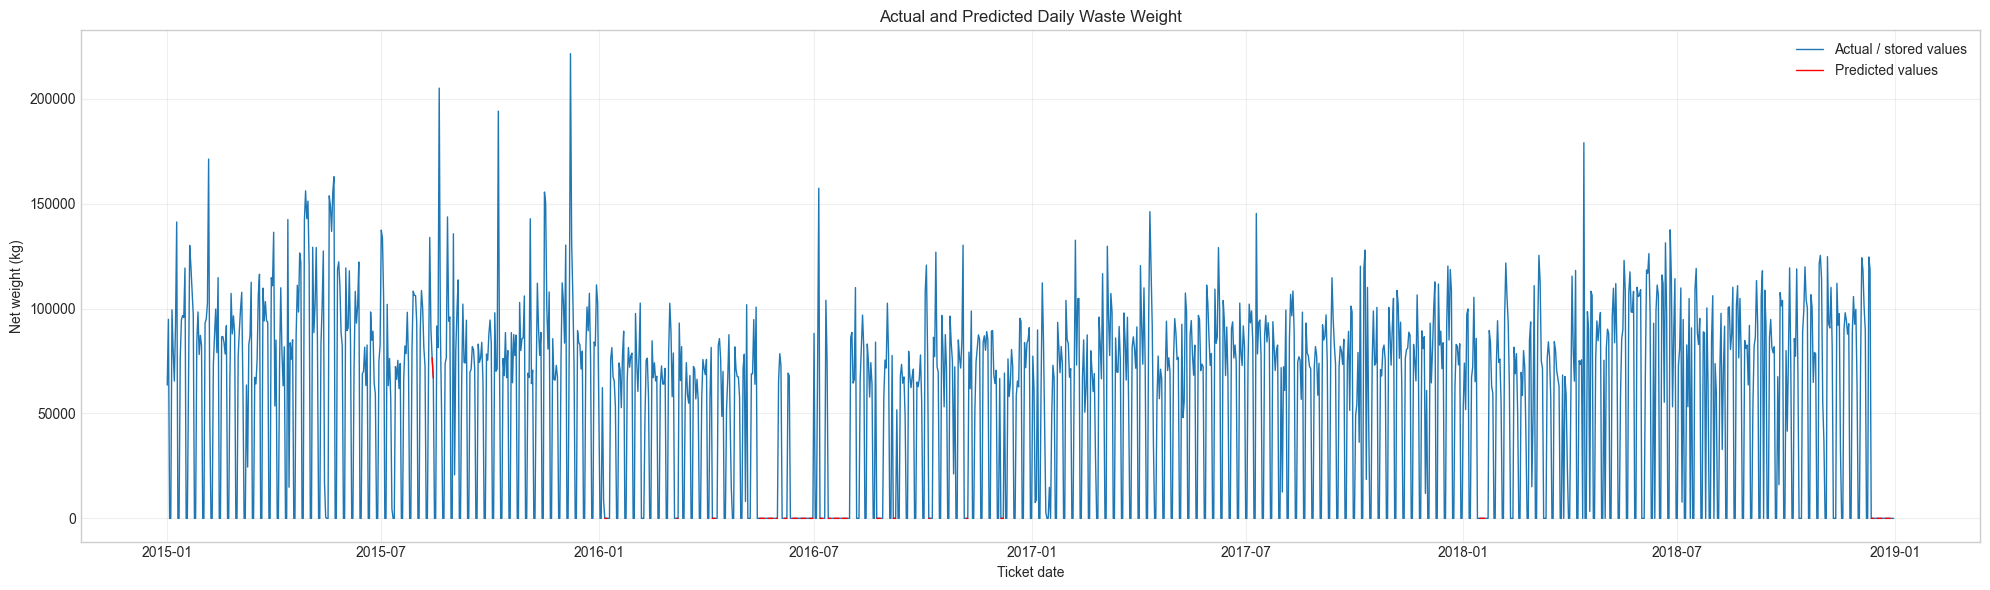

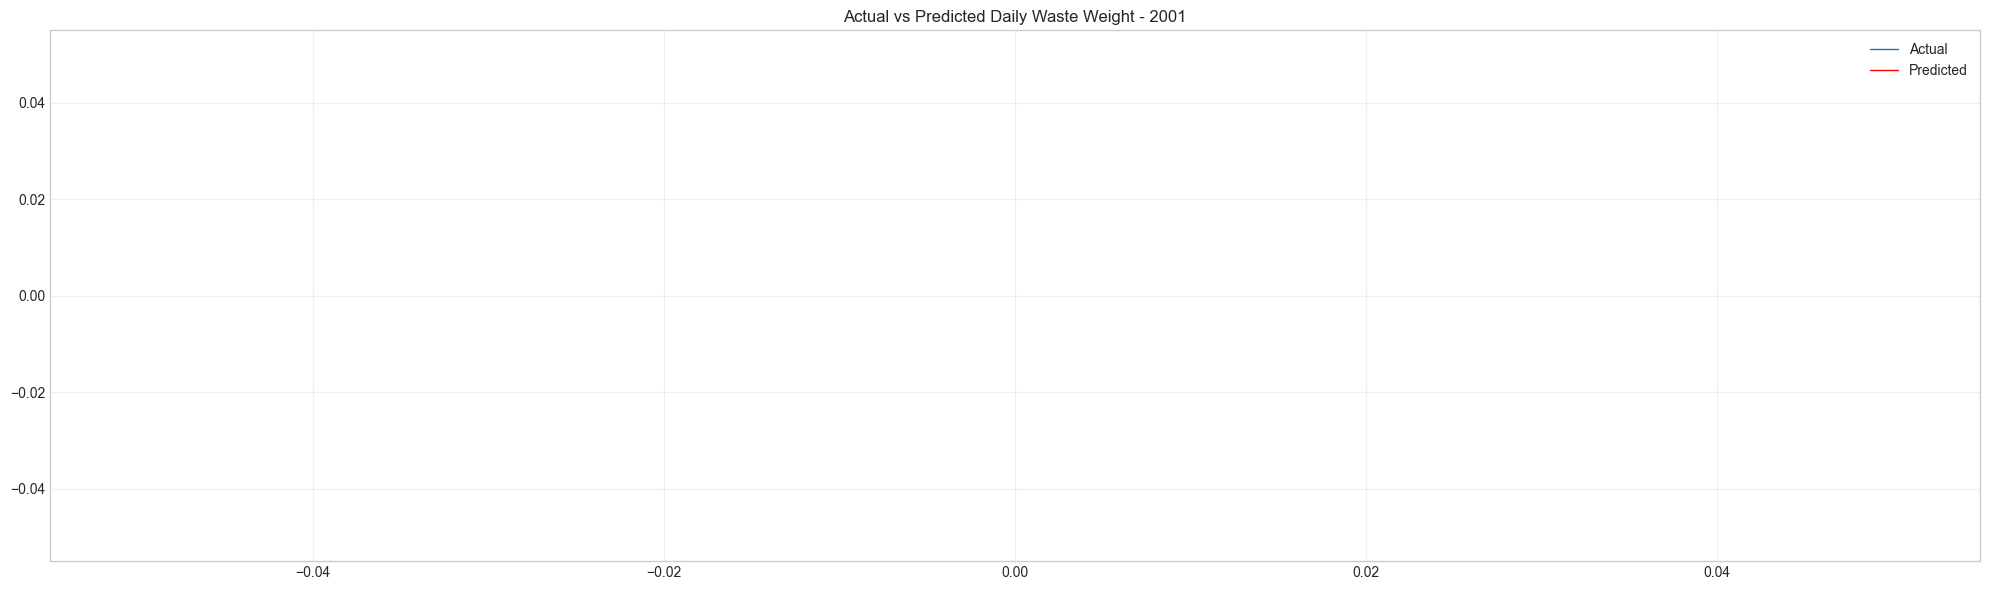

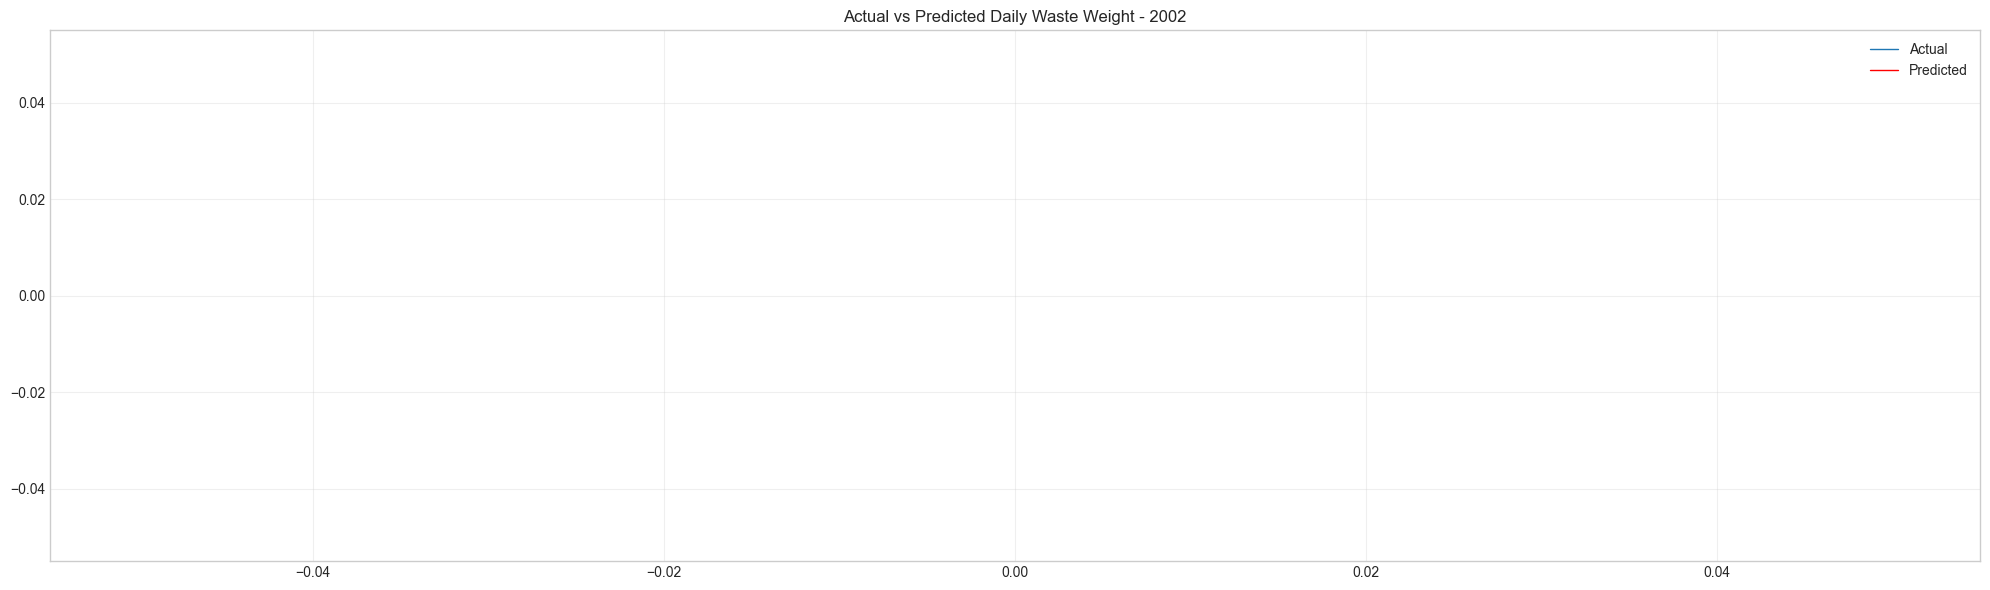

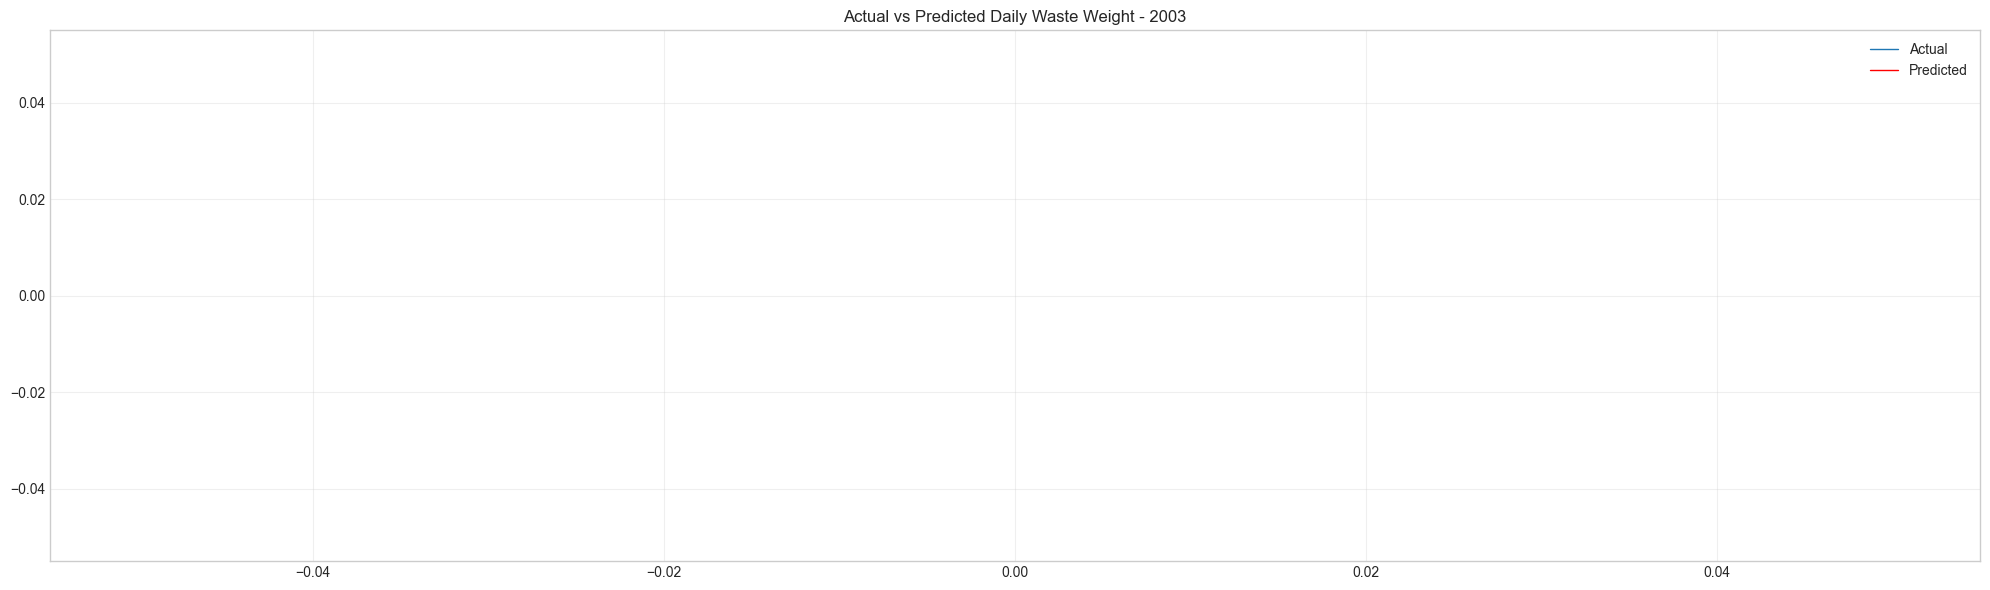

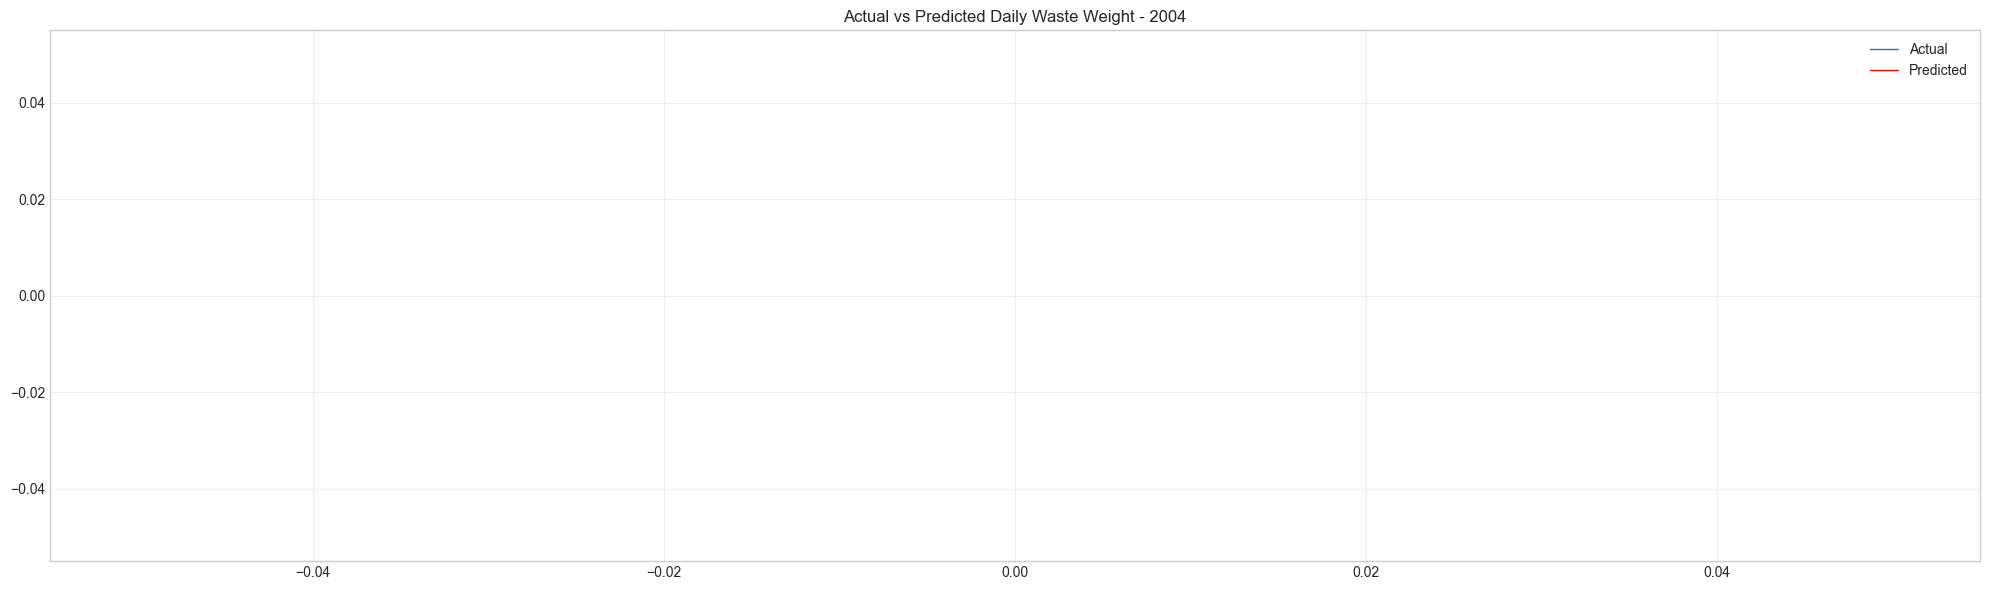

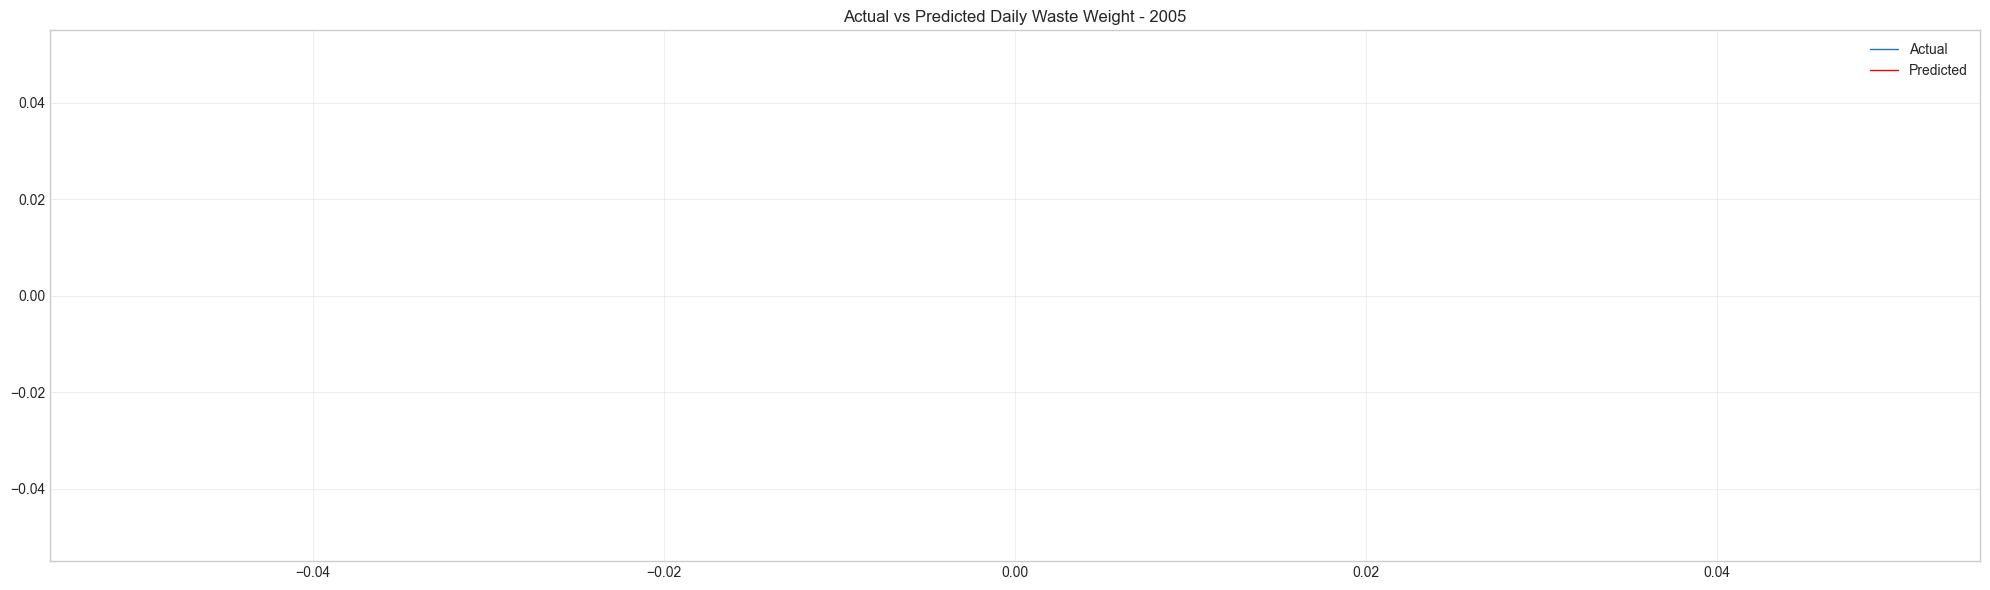

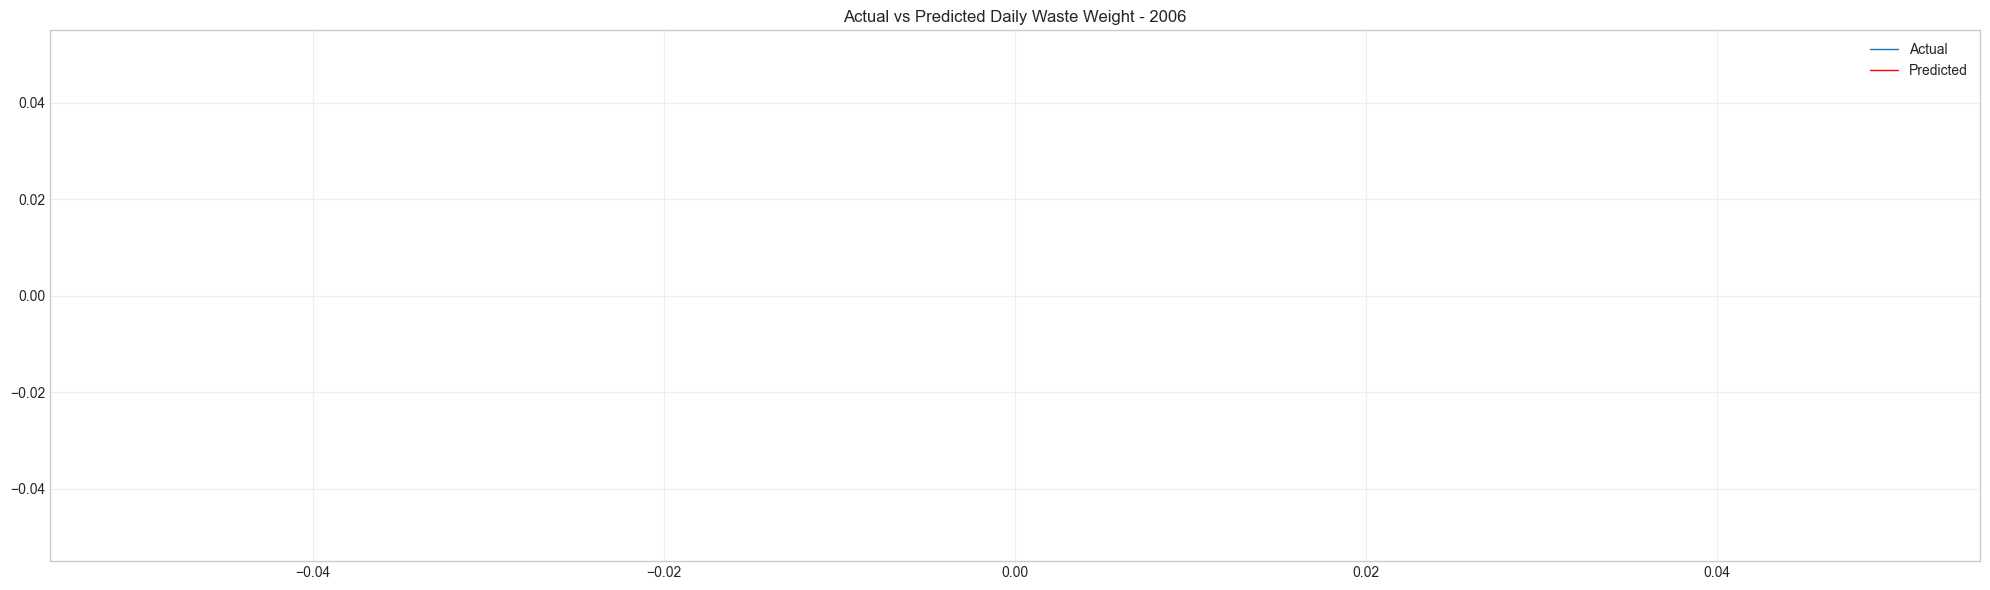

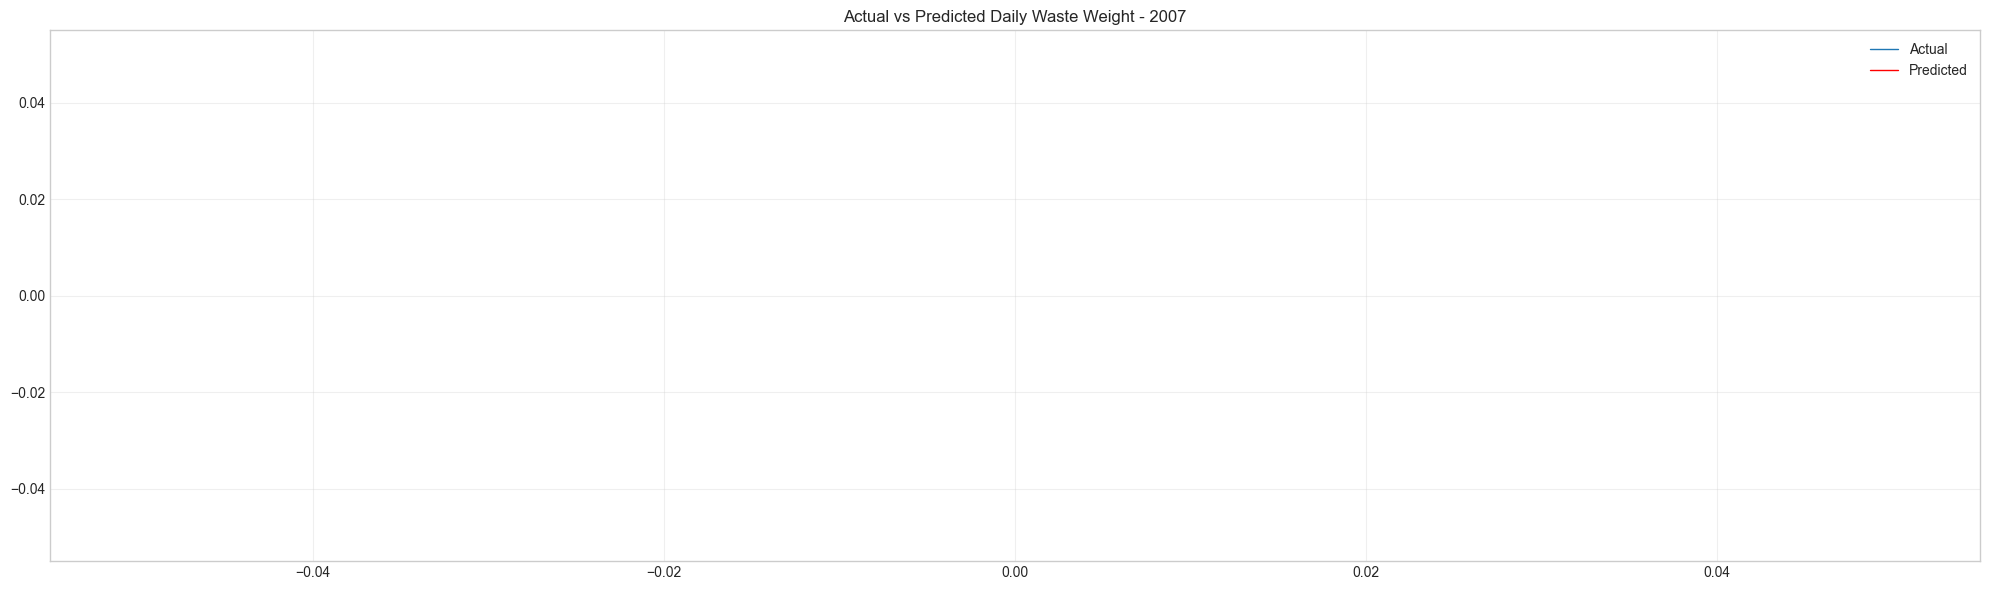

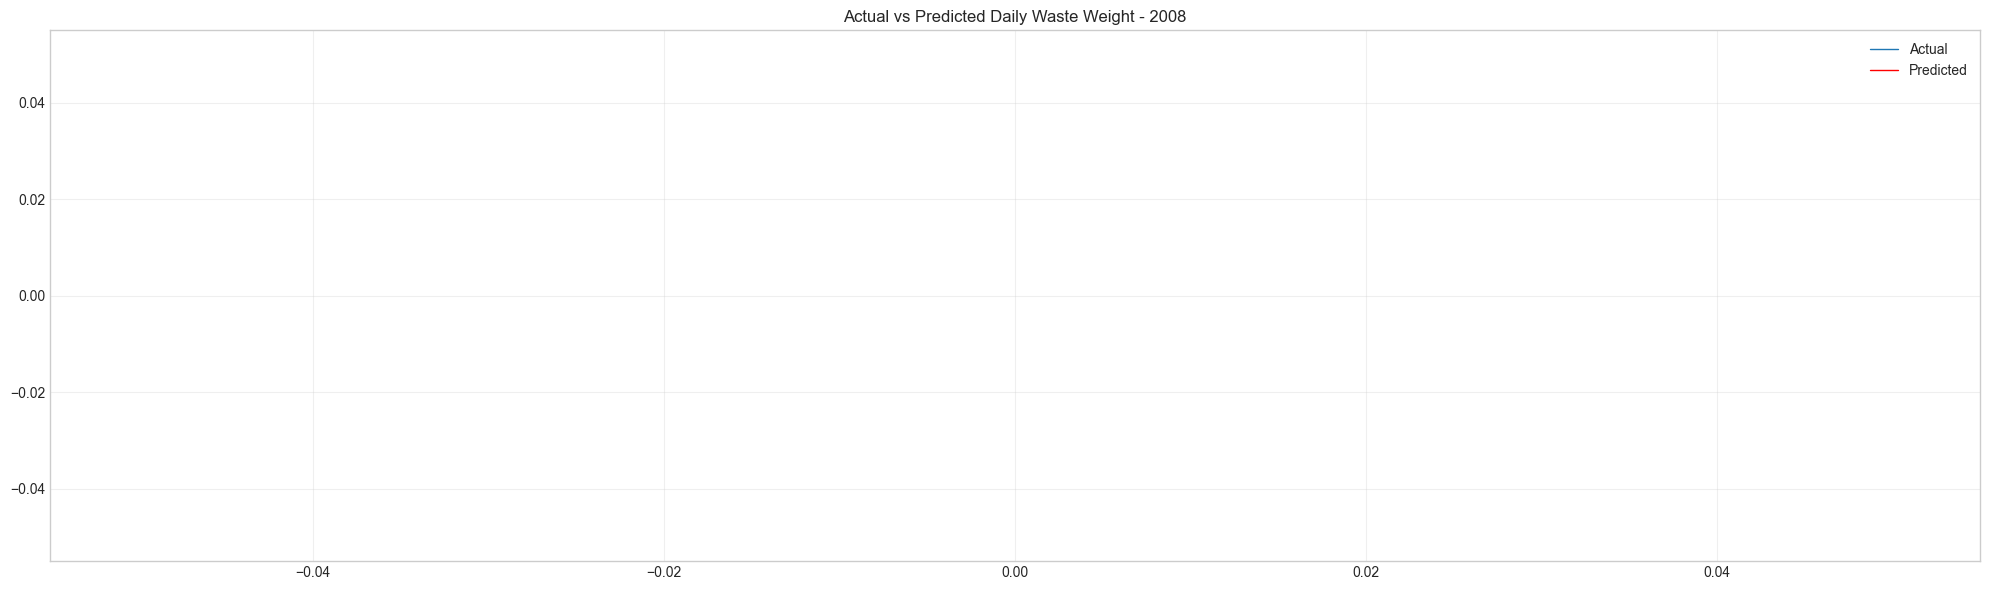

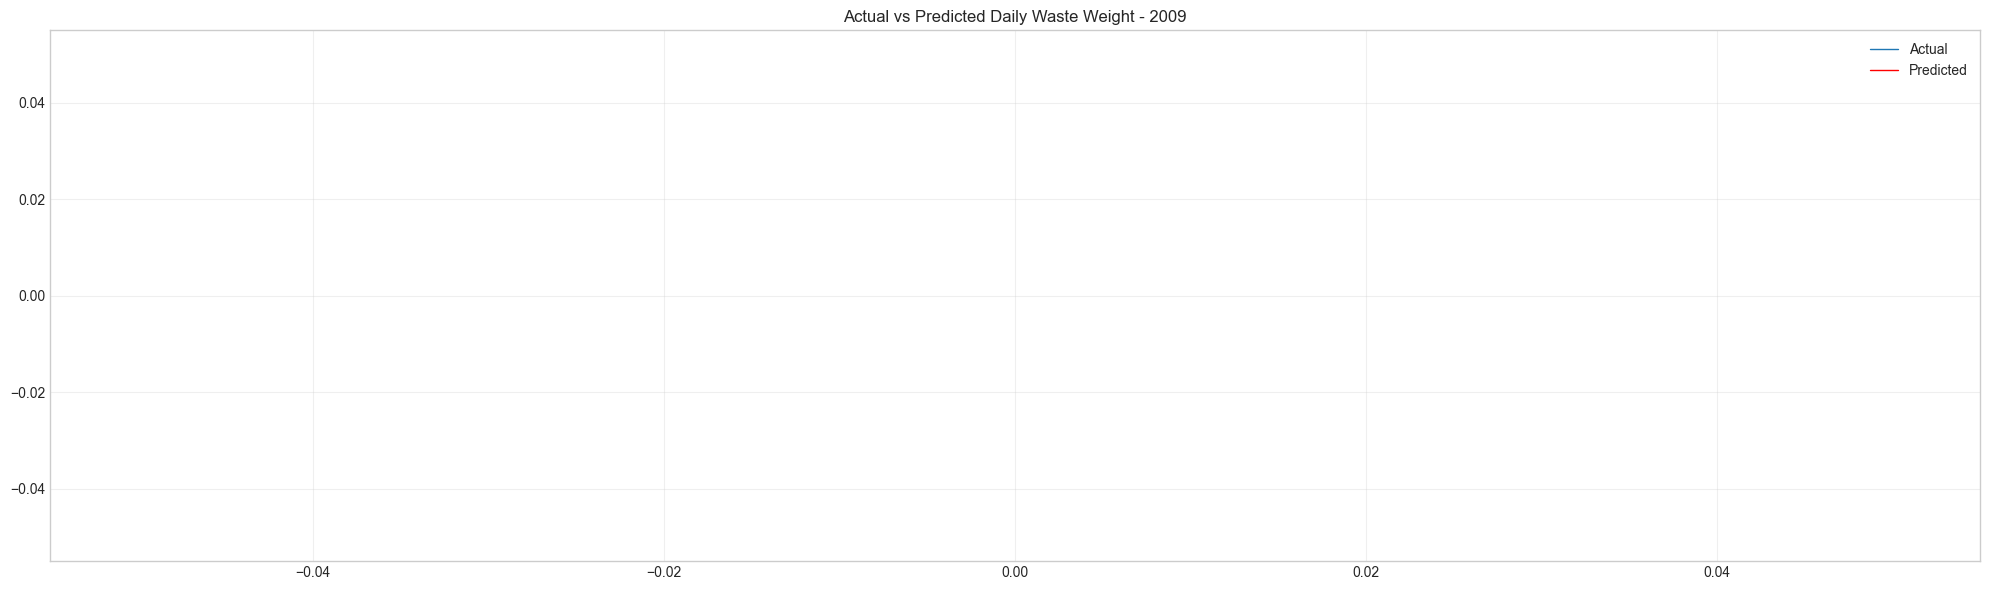

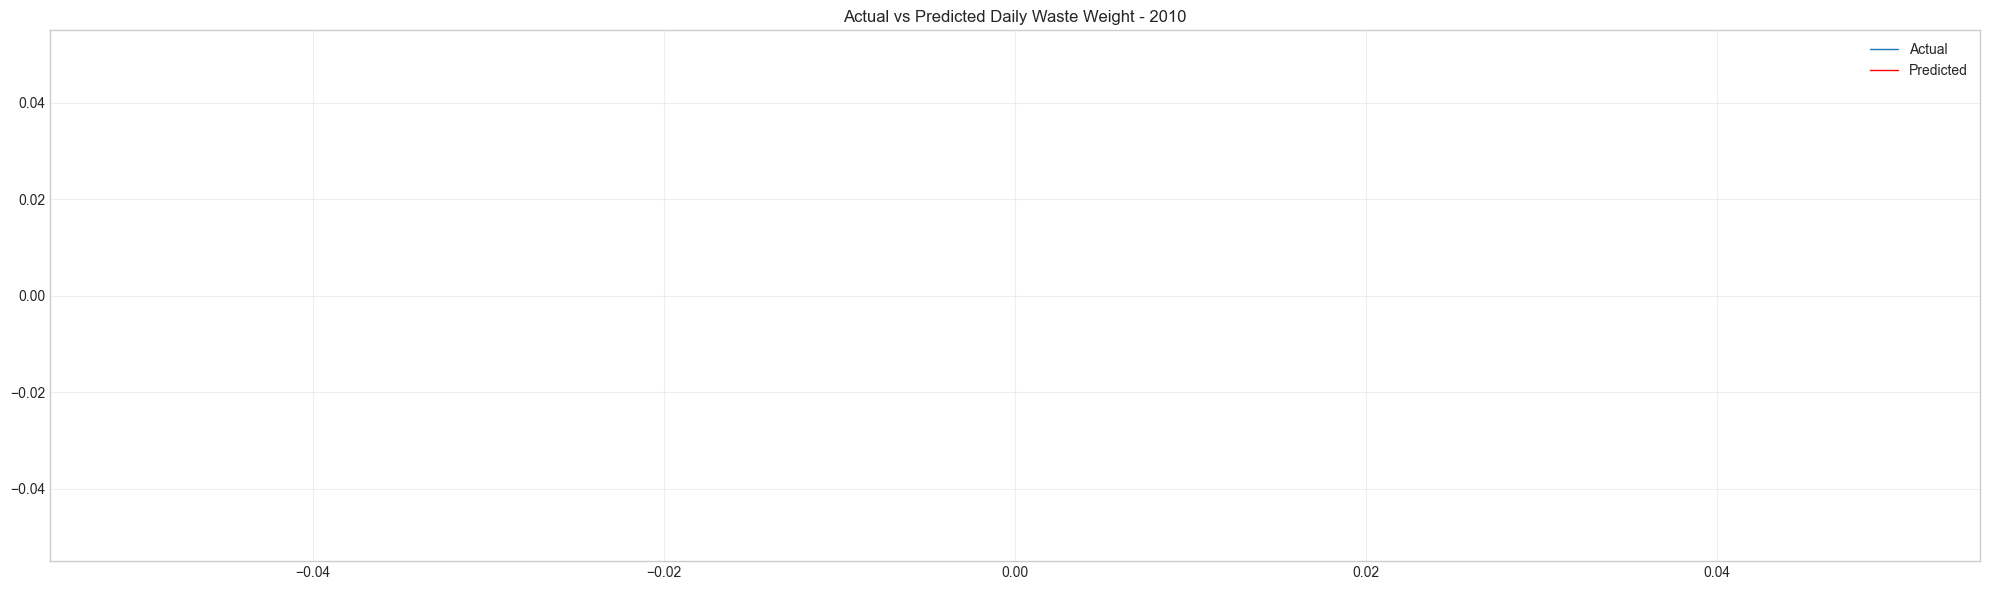

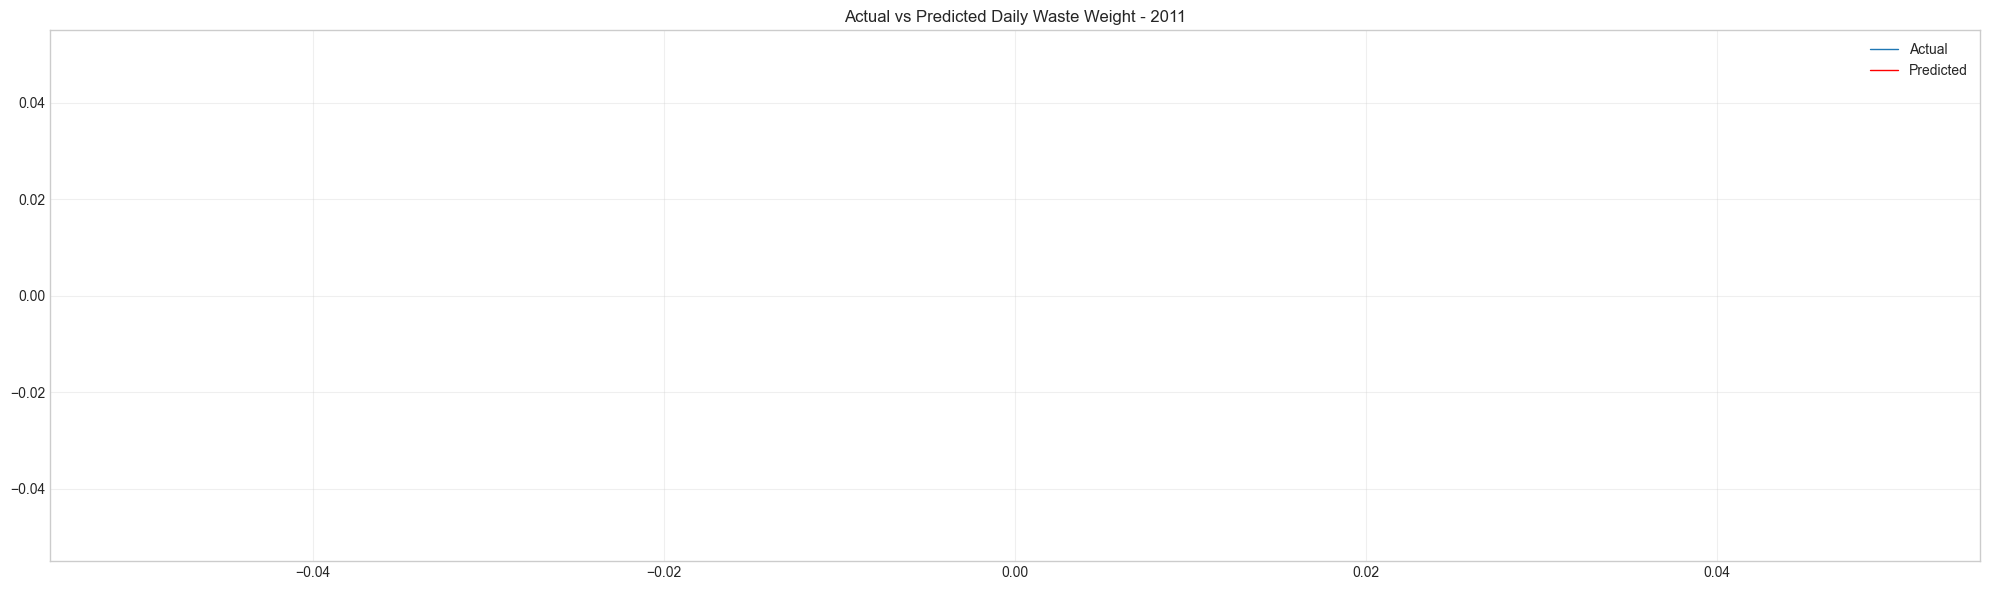

In [64]:
plt.figure(figsize=(20, 6))
plt.plot(df['ticket_date'], df['net_weight_kg'], label='Actual / stored values', linewidth=1)
plt.plot(df['ticket_date'], df['predicted_net_weight_kg'], color='red', label='Predicted values', linewidth=1)
plt.title('Actual and Predicted Daily Waste Weight')
plt.xlabel('Ticket date'); plt.ylabel('Net weight (kg)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


In [65]:
df_backup = df.copy()

In [66]:
del df['predicted_net_weight_kg']

In [67]:
df.columns

Index(['ticket_date', 'net_weight_kg'], dtype='object')

In [68]:
df.to_csv("../processed_datasets/daily_waste_output_Moratuwa.csv", index=False)
print("File saved: daily_waste_output_Moratuwa.csv")

File saved: daily_waste_output_Moratuwa.csv
